# Olist: chuẩn bị dữ liệu phân khúc nhà bán hàng

**Phụ trách: Tzy | Bước 1-3 trong mục Data mining.**

Nguồn: [Olist SQLite trên Kaggle](https://www.kaggle.com/datasets/terencicp/e-commerce-dataset-by-olist-as-an-sqlite-database).
Mục tiêu: một dòng mỗi seller và ma trận đầu vào dùng chung cho K-Means, GMM, DBSCAN. Chưa huấn luyện phân cụm.

Notebook độc lập, chứa mã đồng bộ từ `mining/seller_segmentation.py`. Trên Kaggle, **Add Input** dataset Olist; trên Colab/máy cá nhân đặt `SOURCE` rõ ràng. Nếu thiếu thư viện, cài `numpy pandas scikit-learn matplotlib` trong môi trường notebook rồi chạy lại.

Chỉ tính đơn **delivered** có ngày mua hợp lệ. Seller ngoài cohort được xuất riêng. Đánh giá/giao hàng là thông tin của cả đơn, có thể dùng chung cho nhiều seller. Xem `mining/README.md` trong repo để đọc đầy đủ giả định và định nghĩa.

## Bước 1: Chuẩn bị dữ liệu

Đọc Sellers, Order items, Orders, Products và Reviews. Kiểm tra schema/khóa/giá tiền, xóa trùng hoàn toàn, từ chối khóa mâu thuẫn và khóa ngoại lỗi. Gom review ở mức order trước khi nối để tránh nhân bản doanh số.

`SOURCE` nhận file SQLite hoặc thư mục CSV thô; không dùng file fact/dim sau ETL. Tự tìm chỉ khi có đúng một nguồn phù hợp. Chỉnh ô cấu hình dưới nếu không tự tìm được.

In [1]:
"""Prepare Olist seller segmentation inputs (steps 1-3, without fitting clusters)."""

from __future__ import annotations

import argparse
import hashlib
import json
import platform
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.preprocessing import StandardScaler


REQUIRED = {
    "sellers": ["seller_id", "seller_city", "seller_state"],
    "order_items": ["order_id", "order_item_id", "seller_id", "product_id", "price", "freight_value"],
    "orders": ["order_id", "order_status", "order_purchase_timestamp",
               "order_delivered_customer_date", "order_estimated_delivery_date"],
    "products": ["product_id", "product_category_name"],
    "order_reviews": ["order_id", "review_score"],
}
KEYS = {"sellers": ["seller_id"], "orders": ["order_id"],
        "products": ["product_id"], "order_items": ["order_id", "order_item_id"]}
MODEL_FEATURES = [
    "order_count", "avg_order_value", "category_count", "freight_to_price_ratio",
    "review_score_mean", "late_delivery_rate", "delivery_days_mean", "recency_days", "tenure_days",
]
LOG_FEATURES = ["order_count", "avg_order_value", "category_count", "freight_to_price_ratio",
                "delivery_days_mean", "recency_days", "tenure_days"]


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def load_sources(source):
    """Read the chosen Kaggle SQLite database or its equivalent raw CSV tables."""
    source = Path(source)
    tables, manifest = {}, {}
    if source.is_file():
        if source.suffix.lower() not in {".sqlite", ".sqlite3", ".db"}:
            raise ValueError("Source file must be a SQLite database.")
        with closing(sqlite3.connect(source.resolve().as_uri() + "?mode=ro", uri=True)) as connection:
            available = {row[0] for row in connection.execute("SELECT name FROM sqlite_master WHERE type='table'")}
            for name in REQUIRED:
                if name not in available:
                    raise ValueError(f"Missing SQLite table: {name}")
                tables[name] = pd.read_sql_query(f'SELECT * FROM "{name}"', connection)
        manifest["sqlite"] = {"name": source.name, "sha256": file_sha256(source)}
    elif source.is_dir():
        for name in REQUIRED:
            candidates = [source / f"{name}.csv", source / f"olist_{name}_dataset.csv"]
            existing = [path for path in candidates if path.is_file()]
            if len(existing) != 1:
                raise ValueError(f"Expected one raw CSV for {name}, found {len(existing)} in {source}")
            path = existing[0]
            tables[name] = pd.read_csv(path, dtype={column: "string" for column in REQUIRED[name]
                                                  if column.endswith("_id")})
            manifest[name] = {"name": path.name, "sha256": file_sha256(path)}
    else:
        raise FileNotFoundError(f"Olist source not found: {source}")
    return tables, manifest


def prepare_data(tables):
    """Step 1: validate grain/relationships and retain delivered sale items."""
    tables = {name: frame.copy() for name, frame in tables.items()}
    audit = {"source_rows": {}, "exact_duplicates_removed": {}, "invalid_dates": {}}
    for name, columns in REQUIRED.items():
        frame = tables[name]
        missing = set(columns) - set(frame.columns)
        if missing:
            raise ValueError(f"{name}: missing columns {sorted(missing)}")
        audit["source_rows"][name] = len(frame)
        audit["exact_duplicates_removed"][name] = int(frame.duplicated().sum())
        frame = frame.drop_duplicates().copy()
        for column in frame.columns:
            if column.endswith("_id"):
                frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)
        if name in KEYS:
            keys = KEYS[name]
            if frame[keys].isna().any().any() or frame.duplicated(keys).any():
                raise ValueError(f"{name}: null or conflicting duplicate key {keys}")
        tables[name] = frame
    sellers, items, orders, products, reviews = (tables[name] for name in REQUIRED)
    for column in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
        parsed = pd.to_datetime(orders[column], errors="coerce", format="mixed")
        audit["invalid_dates"][column] = int((orders[column].notna() & parsed.isna()).sum())
        orders[column] = parsed
    for column in ["price", "freight_value"]:
        items[column] = pd.to_numeric(items[column], errors="coerce")
        if not np.isfinite(items[column]).all() or (items[column] < 0).any():
            raise ValueError(f"order_items.{column}: missing, nonnumeric, infinite or negative value")
    for column, dimension, key in [("seller_id", sellers, "seller_id"),
                                    ("product_id", products, "product_id"),
                                    ("order_id", orders, "order_id")]:
        invalid = items[column].isna() | ~items[column].isin(dimension[key])
        if invalid.any():
            raise ValueError(f"order_items.{column}: {int(invalid.sum())} unmatched keys")
    if reviews["order_id"].isna().any() or not reviews["order_id"].isin(orders["order_id"]).all():
        raise ValueError("order_reviews: null or unmatched order_id")
    reviews["review_score"] = pd.to_numeric(reviews["review_score"], errors="coerce")
    invalid_score = reviews["review_score"].isna() | ~reviews["review_score"].between(1, 5)
    audit["invalid_review_scores"] = int(invalid_score.sum())
    reviews.loc[invalid_score, "review_score"] = np.nan
    # Collapse reviews BEFORE joining: multiple reviews must not multiply sale items.
    order_reviews = reviews.groupby("order_id", as_index=False).agg(review_score=("review_score", "mean"))
    joined = items.merge(orders[REQUIRED["orders"]], on="order_id", validate="many_to_one")
    audit["item_rows_by_order_status"] = {str(k): int(v) for k, v in joined["order_status"].value_counts(dropna=False).items()}
    delivered = joined["order_status"].eq("delivered")
    valid_purchase = joined["order_purchase_timestamp"].notna()
    audit["delivered_items_missing_purchase_date"] = int((delivered & ~valid_purchase).sum())
    sales = joined.loc[delivered & valid_purchase].copy()
    if sales.empty:
        raise ValueError("No delivered sale items with a valid purchase date.")
    sales = sales.merge(products[REQUIRED["products"]], on="product_id", validate="many_to_one")
    sales = sales.merge(order_reviews, on="order_id", how="left", validate="many_to_one")
    audit["eligible_item_rows"] = len(sales)
    audit["eligible_orders"] = int(sales["order_id"].nunique())
    audit["multi_seller_orders"] = int((sales.groupby("order_id")["seller_id"].nunique() > 1).sum())
    audit["orders_with_multiple_reviews"] = int((reviews.groupby("order_id").size() > 1).sum())
    return sales, sellers, audit




In [2]:
import os

# Ví dụ Kaggle: Path("/kaggle/input/<dataset-folder>/olist.sqlite")
# Ví dụ máy cá nhân: Path("../data/raw/olist.sqlite")
# Hoặc Path("../data/raw/csv") nếu dùng CSV gốc.
SOURCE = Path(os.environ["OLIST_SOURCE"]) if os.environ.get("OLIST_SOURCE") else None
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT = Path("/kaggle/working/seller_segmentation") if Path("/kaggle/working").exists() else ROOT / "artifacts/seller_segmentation"

if SOURCE is None:
    candidates = []
    for base in [Path("/kaggle/input"), ROOT / "data/raw"]:
        if base.exists():
            candidates.extend(path for path in base.rglob("*") if path.suffix.lower() in {".sqlite", ".sqlite3", ".db"})
            for filename in ["sellers.csv", "olist_sellers_dataset.csv"]:
                candidates.extend(path.parent for path in base.rglob(filename))
    candidates = sorted(set(path.resolve() for path in candidates))
    if len(candidates) != 1:
        raise ValueError(f"Hãy đặt SOURCE tới nguồn Olist cần dùng. Tìm được {len(candidates)} nguồn: {candidates}")
    SOURCE = candidates[0]

tables, manifest = load_sources(SOURCE)
sales, sellers, audit = prepare_data(tables)
display(pd.DataFrame({"table": list(audit["source_rows"]), "rows": list(audit["source_rows"].values())}))
print("Eligible delivered item rows:", len(sales))
print("Multi-seller orders:", audit["multi_seller_orders"])
display(sales[["seller_id", "order_id", "price", "freight_value", "review_score"]].head())

,table,rows
0,sellers,3095
1,order_items,112650
2,orders,99441
3,products,32951
4,order_reviews,99224


Eligible delivered item rows: 110197
Multi-seller orders: 1275


,seller_id,order_id,price,freight_value,review_score
0,48436dade18ac8b2bce089ec2a041202,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,5.0
1,dd7ddc04e1b6c2c614352b383efe2d36,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,4.0
2,5b51032eddd242adc84c38acab88f23d,000229ec398224ef6ca0657da4fc703e,199.00,17.87,5.0
3,9d7a1d34a5052409006425275ba1c2b4,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,4.0
4,df560393f3a51e74553ab94004ba5c87,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,5.0


## Bước 2: Tạo đặc trưng

Gom item thành seller-order rồi mới tính chỉ số theo seller. Nhờ vậy đơn nhiều item không được cho trọng số review lớn hơn. Mốc tham chiếu chung = ngày sau ngày mua cuối trong cohort, không phụ thuộc ngày chạy.

**9 cột mô hình:** số đơn, giá trị đơn trung bình, số ngành hàng, tỷ lệ phí vận chuyển/giá hàng, điểm review trung bình, tỷ lệ giao trễ, số ngày giao trung bình, recency và tenure. Tổng giá hàng, số sản phẩm, địa lý và coverage giữ riêng để diễn giải. Không dùng ID làm đặc trưng số.

Tỷ lệ giao trễ chỉ dùng ngày hợp lệ; giao bất kỳ giờ nào trong ngày hẹn vẫn là đúng hạn. Giá hàng giữ BRL, thời gian tính ngày, tỷ lệ ở thang 0-1 (riêng phí/giá có thể lớn hơn 1).

In [3]:
def create_features(sales, sellers):
    """Step 2: aggregate item values and order-level service metrics separately."""
    # One row per seller-order prevents item-heavy orders receiving extra weight.
    seller_orders = sales.groupby(["seller_id", "order_id"], as_index=False).agg(
        order_sales=("price", "sum"), order_freight=("freight_value", "sum"),
        purchase_at=("order_purchase_timestamp", "first"),
        delivered_at=("order_delivered_customer_date", "first"),
        estimated_at=("order_estimated_delivery_date", "first"),
        review_score=("review_score", "first"),
    )
    duration = (seller_orders["delivered_at"] - seller_orders["purchase_at"]).dt.total_seconds() / 86400
    valid_delivery = duration.notna() & duration.ge(0)
    seller_orders["delivery_days"] = duration.where(valid_delivery)
    valid_deadline = (valid_delivery & seller_orders["estimated_at"].notna()
                      & seller_orders["estimated_at"].ge(seller_orders["purchase_at"].dt.normalize()))
    # Estimated delivery is a calendar date: delivery later on that same date is on time.
    seller_orders["late_delivery"] = (
        seller_orders["delivered_at"].dt.normalize() > seller_orders["estimated_at"].dt.normalize()
    ).astype(float).where(valid_deadline)
    reference_date = sales["order_purchase_timestamp"].max().normalize() + pd.Timedelta(days=1)
    profiles = seller_orders.groupby("seller_id").agg(
        order_count=("order_id", "nunique"), total_sales=("order_sales", "sum"),
        total_freight=("order_freight", "sum"), avg_order_value=("order_sales", "mean"),
        review_score_mean=("review_score", "mean"), reviewed_order_count=("review_score", "count"),
        late_delivery_rate=("late_delivery", "mean"), delivery_days_mean=("delivery_days", "mean"),
        valid_delivery_order_count=("delivery_days", "count"),
        valid_deadline_order_count=("late_delivery", "count"),
        first_sale_at=("purchase_at", "min"), last_sale_at=("purchase_at", "max"),
    )
    item_profiles = sales.groupby("seller_id").agg(
        item_count=("order_item_id", "size"), product_count=("product_id", "nunique"),
        category_count=("product_category_name", "nunique"),
    )
    profiles = profiles.join(item_profiles)
    profiles["freight_to_price_ratio"] = profiles["total_freight"] / profiles["total_sales"].replace(0, np.nan)
    profiles["recency_days"] = (reference_date - profiles["last_sale_at"].dt.normalize()).dt.days
    profiles["tenure_days"] = (reference_date - profiles["first_sale_at"].dt.normalize()).dt.days
    profiles["review_coverage"] = profiles["reviewed_order_count"] / profiles["order_count"]
    profiles = profiles.reset_index().merge(sellers[REQUIRED["sellers"]], on="seller_id", validate="one_to_one")
    profiles = profiles.sort_values("seller_id").reset_index(drop=True)
    excluded = sellers.loc[~sellers["seller_id"].isin(profiles["seller_id"]), REQUIRED["sellers"]].copy()
    excluded["reason"] = "No delivered sale items with a valid purchase date"
    details = {
        "reference_date": reference_date.isoformat(),
        "purchase_start": sales["order_purchase_timestamp"].min().isoformat(),
        "purchase_end": sales["order_purchase_timestamp"].max().isoformat(),
        "eligible_sellers": len(profiles), "excluded_sellers": len(excluded),
        "invalid_delivery_seller_orders": int((~valid_delivery).sum()),
        "invalid_deadline_seller_orders": int((~valid_deadline).sum()),
    }
    return profiles, excluded.sort_values("seller_id"), details




In [4]:
profiles, excluded, details = create_features(sales, sellers)
audit.update(details)
audit["source_manifest"] = manifest
print("Eligible sellers:", len(profiles), "| Excluded sellers:", len(excluded))
print("Reference date:", audit["reference_date"])
display(profiles[["seller_id"] + MODEL_FEATURES].head())
display(profiles[MODEL_FEATURES].describe().T)
display(excluded.head())

Eligible sellers: 2970 | Excluded sellers: 125
Reference date: 2018-08-30T00:00:00


,seller_id,order_count,avg_order_value,category_count,freight_to_price_ratio,review_score_mean,late_delivery_rate,delivery_days_mean,recency_days,tenure_days
0,0015a82c2db000af6aaaf3ae2ecb0532,3,895.000000,1,0.023486,3.666667,0.000000,10.793885,316,338
1,001cca7ae9ae17fb1caed9dfb1094831,195,125.574513,2,0.353488,4.062500,0.061538,13.405805,49,572
2,002100f778ceb8431b7a1020ff7ab48f,50,24.332000,1,0.639947,3.960000,0.180000,16.386809,140,350
3,003554e2dce176b5555353e4f3555ac8,1,120.000000,0,0.161500,5.000000,0.000000,4.646806,258,258
4,004c9cd9d87a3c30c522c48c4fc07416,156,125.446987,1,0.180089,4.162338,0.064103,14.811330,119,580


,count,mean,std,min,25%,50%,75%,max
order_count,2970.0,32.935690,105.407111,1.000000,2.000000,7.000000,22.000000,1819.00000
avg_order_value,2970.0,195.520629,368.473461,6.000000,60.075000,105.143844,187.583944,6735.00000
category_count,2970.0,2.071044,2.109339,0.000000,1.000000,1.000000,2.000000,27.00000
freight_to_price_ratio,2970.0,0.264336,0.225830,0.010972,0.126050,0.205457,0.327251,3.53500
review_score_mean,2965.0,4.176146,0.774805,1.000000,3.968153,4.281690,4.666667,5.00000
late_delivery_rate,2970.0,0.069079,0.156256,0.000000,0.000000,0.000000,0.076923,1.00000
delivery_days_mean,2970.0,12.209893,7.154073,1.214178,8.410119,11.150963,14.232298,189.86316
recency_days,2970.0,130.729630,163.491502,1.000000,14.000000,43.000000,206.750000,696.00000
tenure_days,2970.0,309.928283,198.083311,2.000000,129.000000,294.000000,491.750000,714.00000


,seller_id,seller_city,seller_state,reason
977,001e6ad469a905060d959994f1b41e4f,sao goncalo,RJ,No delivered sale items with a valid purchase ...
2534,02a2272692e13558373c66db98f05e2e,rio de janeiro,RJ,No delivered sale items with a valid purchase ...
1812,0aa124728afc1131dff5655f4c6f487b,alfenas,MG,No delivered sale items with a valid purchase ...
2301,101921376b577a4540dc30e9009133ca,rio claro,SP,No delivered sale items with a valid purchase ...
2362,15ac3c501e2599e4917316fde5c5669a,sao paulo,SP,No delivered sale items with a valid purchase ...


## Bước 3: Tiền xử lý dữ liệu

Điền thiếu bằng median, `log1p` các biến lệch phải rồi `StandardScaler` (z-score, phương sai tổng thể). Dừng nếu một đặc trưng thiếu toàn bộ. Không xóa hoặc clipping outlier tự động: DBSCAN cần có cơ hội nhận diện seller khác biệt. Lưu số ngoại lệ IQR để tham khảo.

Fit trên toàn bộ cohort để phân cụm mô tả. Chưa có bài toán dự báo/tập kiểm tra; nếu sau này dùng cohort mới, tái sử dụng các tham số đã lưu. Review và tỷ lệ trễ của seller ít đơn có độ tin cậy thấp; xem kèm số đơn và coverage khi diễn giải cụm.

In [5]:
def preprocess_features(profiles):
    """Step 3: median imputation, log1p for skewed features, then z-score scaling."""
    raw = profiles.set_index("seller_id")[MODEL_FEATURES].astype(float)
    raw = raw.replace([np.inf, -np.inf], np.nan)
    if (raw < 0).any().any():
        raise ValueError("Unexpected negative feature value.")
    medians = raw.median()
    if medians.isna().any():
        raise ValueError(f"Entirely missing features: {medians.index[medians.isna()].tolist()}")
    imputed = raw.fillna(medians)
    transformed = imputed.copy()
    transformed[LOG_FEATURES] = np.log1p(transformed[LOG_FEATURES])
    scaler = StandardScaler()
    matrix = pd.DataFrame(scaler.fit_transform(transformed), index=raw.index, columns=MODEL_FEATURES)
    if not np.isfinite(matrix.to_numpy()).all() or not matrix.index.is_unique:
        raise ValueError("Model input contains nonfinite values or duplicate sellers.")
    q1, q3 = raw.quantile(.25), raw.quantile(.75)
    outliers = (raw.lt(q1 - 1.5 * (q3 - q1)) | raw.gt(q3 + 1.5 * (q3 - q1))).sum()
    metadata = {
        "feature_order": MODEL_FEATURES, "log1p_features": LOG_FEATURES,
        "imputation": "per-feature median before log1p", "medians": medians.to_dict(),
        "scaler": "StandardScaler (population variance, ddof=0)",
        "mean": dict(zip(MODEL_FEATURES, scaler.mean_.tolist())),
        "scale": dict(zip(MODEL_FEATURES, scaler.scale_.tolist())),
        "variance": dict(zip(MODEL_FEATURES, scaler.var_.tolist())),
        "missing_before_imputation": raw.isna().sum().to_dict(),
        "iqr_outlier_counts": outliers.to_dict(),
        "outlier_policy": "Retain all eligible sellers; no clipping or automatic outlier deletion.",
        "constant_features": [name for name, variance in zip(MODEL_FEATURES, scaler.var_) if variance == 0],
        "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                     "numpy": np.__version__, "scikit_learn": sklearn.__version__},
    }
    return matrix, metadata


def export_results(profiles, excluded, matrix, audit, metadata, output):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    profiles.to_csv(output / "seller_features.csv", index=False, float_format="%.10g")
    excluded.to_csv(output / "excluded_sellers.csv", index=False)
    matrix.to_csv(output / "seller_model_input.csv", index=True, float_format="%.10g")
    profiles[MODEL_FEATURES].describe().T.to_csv(output / "feature_summary.csv", float_format="%.10g")
    for name, value in [("data_quality.json", audit), ("preprocessing.json", metadata)]:
        (output / name).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")


def run(source, output):
    tables, manifest = load_sources(source)
    sales, sellers, audit = prepare_data(tables)
    profiles, excluded, details = create_features(sales, sellers)
    matrix, metadata = preprocess_features(profiles)
    audit.update(details)
    audit["source_manifest"] = manifest
    audit["model_shape"] = list(matrix.shape)
    # Independent controls at item grain, BEFORE seller-order aggregation.
    assert len(profiles) + len(excluded) == len(sellers)
    assert profiles["seller_id"].tolist() == matrix.index.tolist()
    assert profiles["item_count"].sum() == len(sales)
    assert np.isclose(profiles["total_sales"].sum(), sales["price"].sum())
    assert np.isclose(profiles["total_freight"].sum(), sales["freight_value"].sum())
    export_results(profiles, excluded, matrix, audit, metadata, output)
    return profiles, matrix, audit, metadata




In [6]:
matrix, metadata = preprocess_features(profiles)
audit["model_shape"] = list(matrix.shape)
assert len(profiles) + len(excluded) == len(sellers)
assert profiles["seller_id"].tolist() == matrix.index.tolist()
assert profiles["item_count"].sum() == len(sales)
assert np.isclose(profiles["total_sales"].sum(), sales["price"].sum())
assert np.isclose(profiles["total_freight"].sum(), sales["freight_value"].sum())
assert np.isfinite(matrix.to_numpy()).all()
np.testing.assert_allclose(matrix.mean(), 0, atol=1e-10)
nonconstant = matrix.std(ddof=0) > 0
np.testing.assert_allclose(matrix.loc[:, nonconstant].std(ddof=0), 1, atol=1e-10)
export_results(profiles, excluded, matrix, audit, metadata, OUTPUT)
display(pd.DataFrame({"missing_before": metadata["missing_before_imputation"],
                      "iqr_outliers_retained": metadata["iqr_outlier_counts"],
                      "scaled_mean": matrix.mean(), "scaled_std": matrix.std(ddof=0)}))
print("Model shape:", matrix.shape)
print("All grain, total, ID alignment and finite-value checks passed.")
display(matrix.head())

,missing_before,iqr_outliers_retained,scaled_mean,scaled_std
order_count,0,402,-5.622139e-17,1.0
avg_order_value,0,306,7.003750e-16,1.0
category_count,0,399,-2.260818e-16,1.0
freight_to_price_ratio,0,177,0.000000e+00,1.0
review_score_mean,5,152,7.894919e-17,1.0
late_delivery_rate,0,278,3.588600e-17,1.0
delivery_days_mean,0,144,2.105312e-16,1.0
recency_days,0,156,-9.091119e-17,1.0
tenure_days,0,0,8.038463e-16,1.0


Model shape: (2970, 9)
All grain, total, ID alignment and finite-value checks passed.


,order_count,avg_order_value,category_count,freight_to_price_ratio,review_score_mean,late_delivery_rate,delivery_days_mean,recency_days,tenure_days
seller_id,,,,,,,,,
0015a82c2db000af6aaaf3ae2ecb0532,-0.662588,2.186383,-0.641986,-1.314341,-0.658444,-0.442160,-0.043762,1.220346,0.431050
001cca7ae9ae17fb1caed9dfb1094831,2.171502,0.114363,0.235270,0.534063,-0.147053,-0.048263,0.428323,-0.032133,0.973507
002100f778ceb8431b7a1020ff7ab48f,1.191112,-1.588859,-0.641986,1.803805,-0.279476,0.709989,0.872161,0.670940,0.467000
003554e2dce176b5555353e4f3555ac8,-1.167349,0.066677,-2.141665,-0.477690,1.064134,-0.442160,-1.781757,1.083307,0.152866
004c9cd9d87a3c30c522c48c4fc07416,2.009933,0.113295,-0.641986,-0.372678,-0.018070,-0.031850,0.648013,0.561574,0.987836


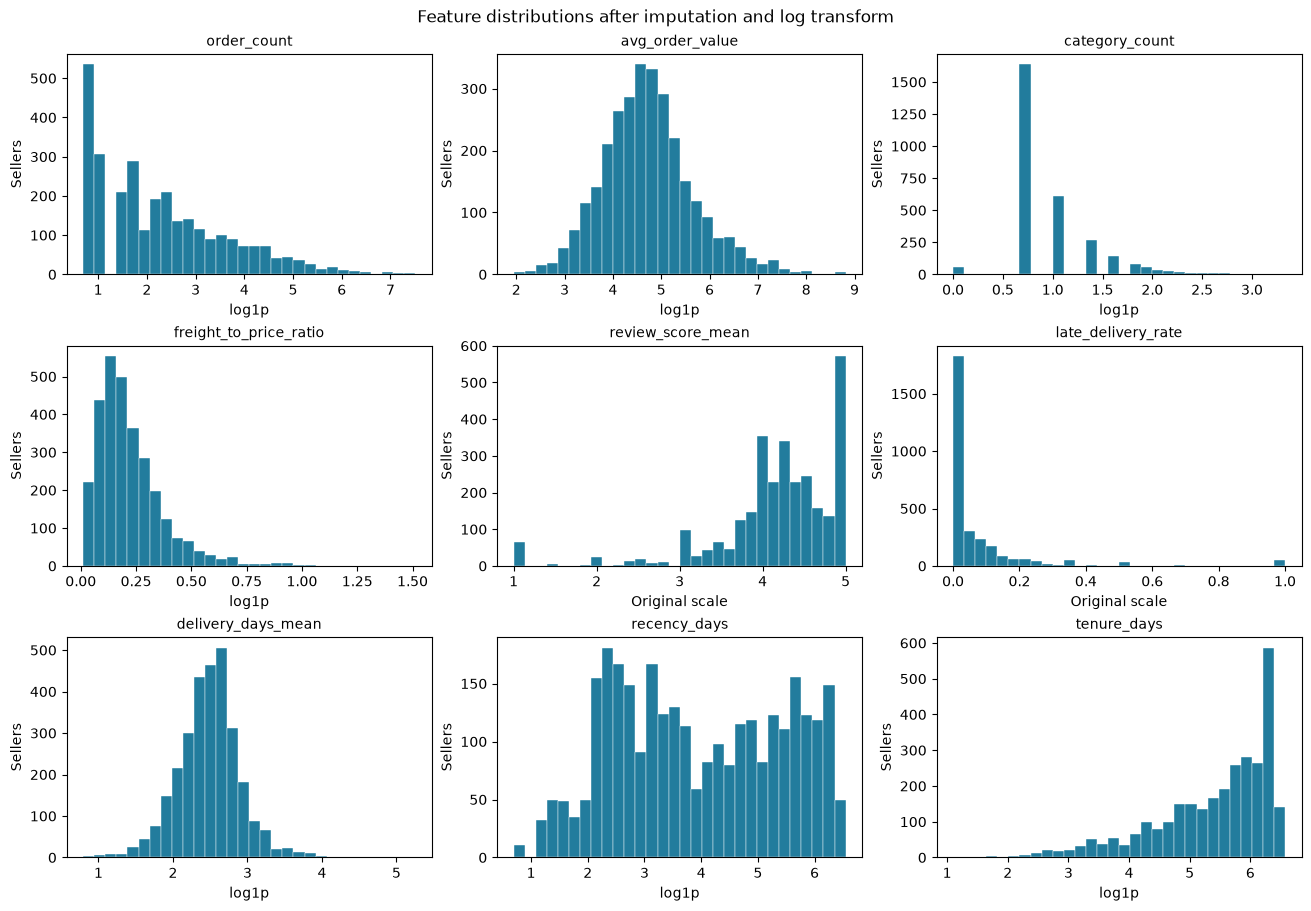

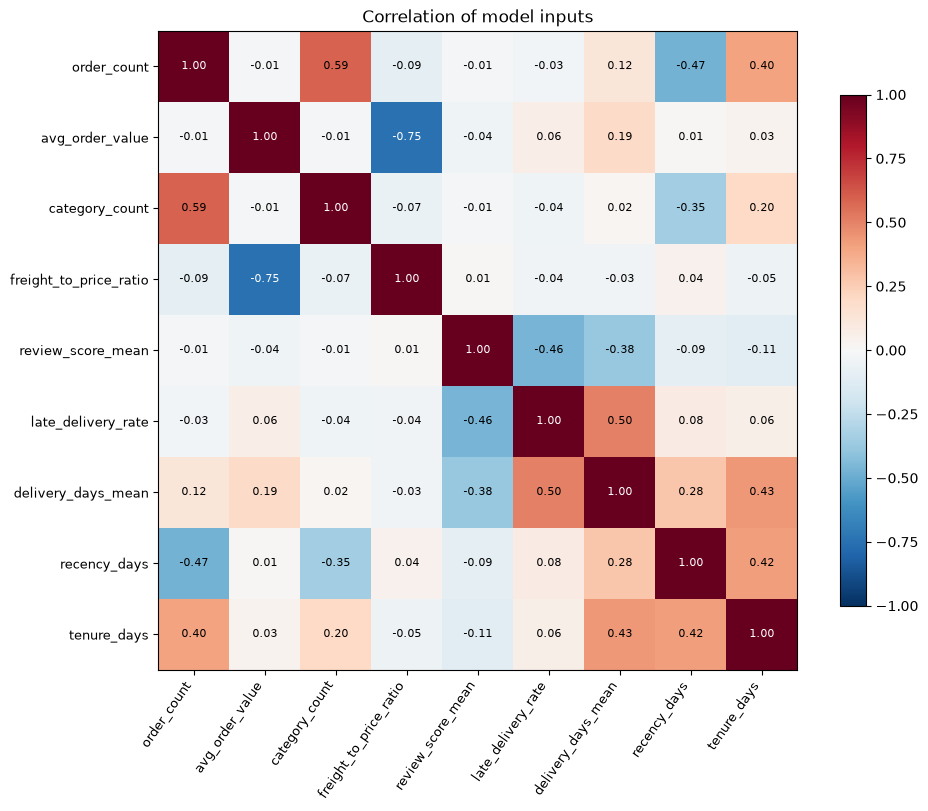

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(13, 9), constrained_layout=True)
for ax, feature in zip(axes.flat, MODEL_FEATURES):
    values = profiles[feature].fillna(metadata["medians"][feature])
    if feature in LOG_FEATURES:
        values = np.log1p(values)
    ax.hist(values, bins=30, color="#227c9d", edgecolor="white", linewidth=.3)
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("log1p" if feature in LOG_FEATURES else "Original scale")
    ax.set_ylabel("Sellers")
fig.suptitle("Feature distributions after imputation and log transform")
plt.show()

corr = matrix.corr()
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(MODEL_FEATURES)), MODEL_FEATURES, rotation=55, ha="right", fontsize=9)
ax.set_yticks(range(len(MODEL_FEATURES)), MODEL_FEATURES, fontsize=9)
for row in range(len(MODEL_FEATURES)):
    for col in range(len(MODEL_FEATURES)):
        value = corr.iloc[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > .65 else "black")
fig.colorbar(image, ax=ax, shrink=.8)
ax.set_title("Correlation of model inputs")
plt.show()

### Bàn giao cho bước huấn luyện

Các file được xuất vào `artifacts/seller_segmentation` (Kaggle: `/kaggle/working/seller_segmentation`).

- `seller_features.csv`: đặc trưng trước impute/log/scale, dùng diễn giải cụm.
- `seller_model_input.csv`: seller ID + 9 đặc trưng đã chuẩn hóa.
- `excluded_sellers.csv`: seller ngoài cohort và lý do.
- `preprocessing.json`: thứ tự cột, median/log/mean/scale, số thiếu/ngoại lệ và phiên bản.
- `data_quality.json`: hash nguồn, kiểm tra dữ liệu, thời gian và quy mô cohort.
- `feature_summary.csv`: thống kê mô tả.

Dùng **cùng ma trận và cùng thứ tự seller** để so sánh K-Means/GMM/DBSCAN. Không đưa `seller_id` vào X. Chưa có nhãn cụm hoặc kết luận phân khúc trong notebook này.

In [8]:
model_input = pd.read_csv(OUTPUT / "seller_model_input.csv")
seller_ids = model_input.pop("seller_id")
X = model_input.to_numpy()
np.testing.assert_allclose(X, matrix.to_numpy(), rtol=1e-8, atol=1e-8)
assert seller_ids.tolist() == profiles["seller_id"].tolist()
print(f"Ready for clustering: {X.shape[0]} sellers x {X.shape[1]} features")

Ready for clustering: 2970 sellers x 9 features
